# 01. Chất lượng dữ liệu

Kiểm tra dữ liệu trong PostgreSQL (`vn_stock`) trước khi phân tích, và chốt các **quy tắc lọc** dùng cho các notebook sau.

- Nguồn: API Vietcap, crawl 21–27/10/2026, ngày chốt **30/09/2026**.
- Phạm vi: 100 mã VN100 (thành phần **hiện tại**), VN-Index, VN30 index, BCTC năm FY2020–2025.
- Kiểm tra tự động khi nạp: `sql/integrity_checks.sql` (chạy trong `src/load_to_db.py`).

In [1]:
import sys
sys.path.insert(0, "../src")
import pandas as pd, numpy as np, matplotlib.pyplot as plt, seaborn as sns
from db import query
from config import RAW_DIR
pd.set_option("display.width", 160)
sns.set_theme(style="whitegrid")

## 1. Quy mô dữ liệu

In [2]:
query("""
SELECT 'dim_stock' AS bang, COUNT(*) AS so_dong FROM dim_stock UNION ALL
SELECT 'dim_date', COUNT(*) FROM dim_date UNION ALL
SELECT 'fact_price', COUNT(*) FROM fact_price UNION ALL
SELECT 'fact_index_price', COUNT(*) FROM fact_index_price UNION ALL
SELECT 'fact_financials', COUNT(*) FROM fact_financials""")

,bang,so_dong
0,dim_stock,100
1,dim_date,2099
2,fact_price,135845
3,fact_index_price,2858
4,fact_financials,595


In [3]:
stocks = query("SELECT * FROM dim_stock")
print(stocks.groupby(["industry_l1"]).size().sort_values(ascending=False).to_string())
print()
print(stocks.fs_template.value_counts().to_string())

industry_l1
Tài chính             49
Công nghiệp           15
Hàng tiêu dùng        13
Nguyên vật liệu        7
Tiện ích cộng đồng     6
Dịch vụ tiêu dùng      5
Dầu khí                3
Công nghệ              2

fs_template
thuong         68
ngan_hang      19
chung_khoan    12
bao_hiem        1


## 2. Độ phủ giá: số phiên của mỗi mã so với VN-Index

Tỷ lệ = số phiên của mã / số phiên VN-Index trong năm. Ô < 80% là mã niêm yết muộn hoặc có giai đoạn ngừng giao dịch.

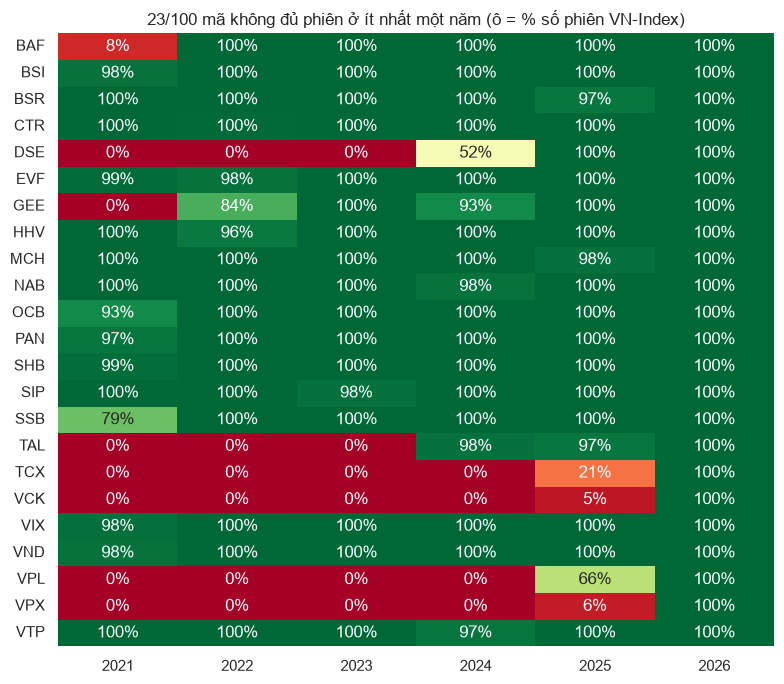

Mã-năm có dưới 80% số phiên (đã niêm yết):
ticker  year    share
   BAF  2021 0.084000
   SSB  2021 0.792000
   DSE  2024 0.520000
   TCX  2025 0.208835
   VCK  2025 0.048193
   VPL  2025 0.662651
   VPX  2025 0.060241


In [4]:
cov = query("""
WITH s AS (SELECT ticker, EXTRACT(YEAR FROM date)::int AS year, COUNT(*) AS n FROM fact_price GROUP BY 1, 2),
     i AS (SELECT EXTRACT(YEAR FROM date)::int AS year, COUNT(*) AS n FROM fact_index_price WHERE index_code = 'VNINDEX' GROUP BY 1)
SELECT s.ticker, s.year, s.n::float / i.n AS share FROM s JOIN i USING (year)""")
share = cov.pivot(index="ticker", columns="year", values="share").reindex(stocks.ticker).fillna(0)
incomplete = share[(share < 0.999).any(axis=1)]
fig, ax = plt.subplots(figsize=(8, 7))
sns.heatmap(incomplete, annot=True, fmt=".0%", cmap="RdYlGn", vmin=0, vmax=1, cbar=False, ax=ax)
ax.set_title(f"{len(incomplete)}/100 mã không đủ phiên ở ít nhất một năm (ô = % số phiên VN-Index)")
ax.set_xlabel(""); ax.set_ylabel("")
plt.tight_layout(); plt.show()
print("Mã-năm có dưới 80% số phiên (đã niêm yết):")
print(cov[(cov.share < 0.8)].sort_values(["year", "ticker"]).to_string(index=False))

## 3. Mã niêm yết sau đầu kỳ (lịch sử ngắn)

In [5]:
late = stocks[stocks.first_trade_date > pd.Timestamp("2021-01-05").date()][["ticker", "company_name", "industry_l2", "first_trade_date"]]
late.sort_values("first_trade_date")

,ticker,company_name,industry_l2,first_trade_date
89,VIX,Công ty Cổ phần Chứng khoán VIX,Dịch vụ tài chính,2021-01-08
56,OCB,Ngân hàng Thương mại Cổ phần Phương Đông,Ngân hàng,2021-01-28
72,SSB,Ngân hàng Thương mại Cổ phần Đông Nam Á,Ngân hàng,2021-03-24
2,BAF,Công ty Cổ phần Nông nghiệp BAF Việt Nam,Thực phẩm và đồ uống,2021-12-03
29,GEE,Công ty Cổ phần Điện lực Gelex,Hàng và dịch vụ công nghiệp,2022-03-08
75,TAL,Công Ty Cổ Phần Đầu Tư Bất Động Sản Taseco,Bất động sản,2024-01-09
21,DSE,Công ty Cổ phần Chứng khoán DNSE,Dịch vụ tài chính,2024-07-01
95,VPL,Công ty Cổ phần Vinpearl,Du lịch và giải trí,2025-05-13
78,TCX,Công ty Cổ phần Chứng khoán Kỹ Thương,Dịch vụ tài chính,2025-10-21
96,VPX,Công ty Cổ phần Chứng khoán VPBank,Dịch vụ tài chính,2025-12-11


## 4. Bất thường trong giá

- **Phiên khối lượng = 0**: không khớp lệnh, giá O=H=L=C.
- **Thiếu phiên giữa kỳ**: mã có dòng ở trước và sau, nhưng thiếu phiên mà VN-Index có giao dịch.
- **Biến động > 7,5%/phiên**: vượt biên độ HOSE (±7%). Hợp lệ với mã khi đó còn niêm yết ở HNX (±10%) hoặc UPCoM (±15%).

In [6]:
print(query("""SELECT ticker, COUNT(*) AS phien_volume_0, MIN(date) AS tu, MAX(date) AS den
FROM fact_price WHERE volume = 0 GROUP BY 1 ORDER BY 2 DESC""").to_string(index=False))

gaps = query("""
WITH r AS (SELECT ticker, MIN(date) a, MAX(date) b, COUNT(*) n FROM fact_price GROUP BY 1)
SELECT r.ticker, COUNT(i.date) - r.n AS phien_thieu
FROM r JOIN fact_index_price i ON i.index_code = 'VNINDEX' AND i.date BETWEEN r.a AND r.b
GROUP BY r.ticker, r.n HAVING COUNT(i.date) > r.n ORDER BY 2 DESC""")
print(f"\n{len(gaps)} mã thiếu phiên giữa kỳ, tổng {gaps.phien_thieu.sum()} phiên:")
print(gaps.to_string(index=False))

big = query("""
SELECT ticker, COUNT(*) AS so_phien FROM (
  SELECT ticker, close / LAG(close) OVER (PARTITION BY ticker ORDER BY date) - 1 AS r FROM fact_price) x
WHERE ABS(r) > 0.075 GROUP BY 1 ORDER BY 2 DESC""")
print(f"\nPhiên biến động > 7,5%: {big.so_phien.sum()} phiên ở {len(big)} mã")
print(big.to_string(index=False))

ticker  phien_volume_0         tu        den
   HHV              30 2021-01-07 2021-05-27
   GEE              13 2022-09-19 2024-04-17
   TAL               3 2024-09-10 2024-10-28

14 mã thiếu phiên giữa kỳ, tổng 97 phiên:
ticker  phien_thieu
   GEE           18
   HHV            9
   TAL            8
   EVF            8
   BSR            8
   VTP            7
   PAN            7
   VND            6
   NAB            6
   BSI            6
   MCH            5
   SIP            5
   SHB            3
   CTR            1

Phiên biến động > 7,5%: 218 phiên ở 14 mã
ticker  so_phien
   GEE        38
   BSR        34
   HHV        22
   SIP        20
   SHB        18
   NAB        14
   BSI        13
   VND        12
   VTP        11
   MCH        10
   TAL         9
   CTR         8
   EVF         6
   PAN         3


## 5. Giá trị giao dịch: không dùng số của API

Trường giá trị giao dịch (`accumulatedValue`) của API có 2 vấn đề:
1. **Thiếu** ở khoảng 28% số phiên.
2. **Lệch đơn vị trước 2025**: so với `close × volume`, số của API nhỏ hơn hàng chục lần và không ổn định, có phiên bằng 0.

→ `clean.py` tính lại **toàn bộ** `value_mil_vnd = close × volume / 1e6`. Sai số đã biết: `close` là giá điều chỉnh (thấp hơn giá giao dịch thật khi có cổ tức hoặc chia tách), nên giá trị quá khứ bị tính thấp đi vài %. Không ảnh hưởng nhiều khi so sánh **tương đối** giữa các mã và ngành.

In [7]:
raw = pd.concat(pd.read_csv(f, usecols=["ticker", "date", "close", "volume", "value_mil_vnd"])
                for f in (RAW_DIR / "prices").glob("*.csv"))
raw = raw[~raw.ticker.isin(["VNINDEX", "VN30"])]
raw["year"] = raw.date.str[:4]
print(f"Phiên API thiếu giá trị: {raw.value_mil_vnd.isna().sum():,} / {len(raw):,} ({raw.value_mil_vnd.isna().mean():.1%})")
ok = raw[raw.value_mil_vnd > 0]
ratio = (ok.close * ok.volume / 1e6 / ok.value_mil_vnd).groupby(ok.year).median()
print("\nTrung vị (close × volume) / (giá trị của API) theo năm. Đúng đơn vị thì ≈ 1:")
print(ratio.round(2).to_string())
print(f"\nPhiên API trả giá trị = 0: {(raw.value_mil_vnd == 0).sum():,}")

Phiên API thiếu giá trị: 39,055 / 135,845 (28.7%)

Trung vị (close × volume) / (giá trị của API) theo năm. Đúng đơn vị thì ≈ 1:
year
2022    76.05
2023    91.82
2024    19.31
2025     0.88
2026     0.98

Phiên API trả giá trị = 0: 21


## 6. Báo cáo tài chính

In [8]:
fin = query("""SELECT f.*, s.fs_template FROM fact_financials f JOIN dim_stock s USING (ticker)""")
print(pd.crosstab(fin.fiscal_year, fin.fs_template, margins=True, margins_name="Tổng").to_string())
print("\nÔ trống theo mẫu BCTC:")
print(fin.groupby("fs_template")[["revenue", "net_income", "roe", "pe", "pb", "gross_margin", "debt_to_equity"]]
      .agg(lambda s: s.isna().sum()).to_string())

fs_template  bao_hiem  chung_khoan  ngan_hang  thuong  Tổng
fiscal_year                                                
2020                1           12         19      65    97
2021                1           12         19      66    98
2022                1           12         19      68   100
2023                1           12         19      68   100
2024                1           12         19      68   100
2025                1           12         19      68   100
Tổng                6           72        114     403   595

Ô trống theo mẫu BCTC:
             revenue  net_income  roe  pe  pb  gross_margin  debt_to_equity
fs_template                                                                
bao_hiem           0           0    0   0   0             6               6
chung_khoan        0           0   19  19  19            19              19
ngan_hang          0           0    2   2   2           114             114
thuong             0           0    7   7   7           

### Ngày công bố BCTC

`available_date` là ngày công bố thật (`publicDate` từ API). Đây là ngày sớm nhất nhà đầu tư biết số liệu, dùng để ghép với giá ở Q2, tránh look-ahead bias.

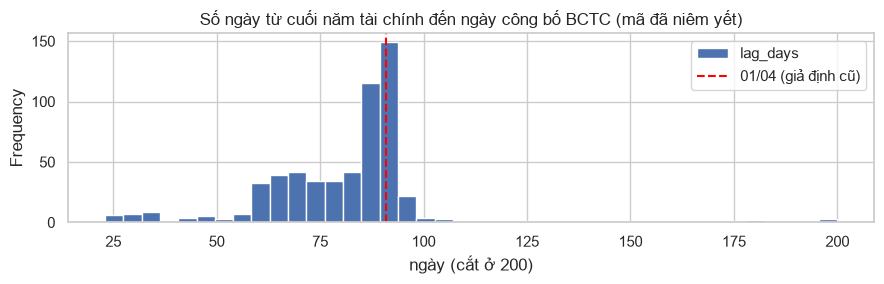

count    570.0
mean      81.0
std       23.0
min       23.0
50%       86.0
90%       92.0
95%       95.0
max      284.0
Công bố sau 01/04: 75 / 570 BCTC (13%)
ticker  fiscal_year available_date  lag_days
   BVH         2020     2021-10-11       284
   VCI         2020     2021-10-11       284
   CTS         2020     2021-09-24       267
   HT1         2020     2021-06-30       181
   FTS         2020     2021-06-28       179
   SBT         2020     2021-06-23       174
   VJC         2021     2022-06-21       172
   BCM         2020     2021-06-09       160
   VPI         2020     2021-05-19       139
   VJC         2024     2025-05-14       134
   VJC         2020     2021-05-07       127


In [9]:
fin["lag_days"] = (pd.to_datetime(fin.available_date) - pd.to_datetime(fin.fiscal_year.astype(str) + "-12-31")).dt.days
listed = fin.merge(stocks[["ticker", "first_trade_date"]])
listed = listed[pd.to_datetime(listed.available_date) >= pd.to_datetime(listed.first_trade_date)]
ax = listed.lag_days.clip(upper=200).plot.hist(bins=40, figsize=(9, 3), title="Số ngày từ cuối năm tài chính đến ngày công bố BCTC (mã đã niêm yết)")
ax.axvline(91, color="red", ls="--", label="01/04 (giả định cũ)"); ax.legend(); ax.set_xlabel("ngày (cắt ở 200)")
plt.tight_layout(); plt.show()
print(listed.lag_days.describe(percentiles=[.5, .9, .95]).round(0).to_string())
print(f"Công bố sau 01/04: {(listed.lag_days > 91).sum()} / {len(listed)} BCTC ({(listed.lag_days > 91).mean():.0%})")
print(listed[listed.lag_days > 120][["ticker", "fiscal_year", "available_date", "lag_days"]].sort_values("lag_days", ascending=False).to_string(index=False))

## 7. Kết luận: quy tắc dùng cho các notebook sau

**Dữ liệu đủ tin cậy để phân tích.** Không trùng khóa, không có giá vô lý, ngày giao dịch khớp VN-Index, lợi nhuận FPT và VCB khớp BCTC đã công bố.

| # | Vấn đề | Quy tắc |
|---|---|---|
| 1 | 7 mã–năm có dưới 80% số phiên VN-Index (BAF 2021, SSB 2021, DSE 2024, TCX/VCK/VPL/VPX 2025) | **Bỏ khi tính chỉ số theo năm** (`metrics.MIN_SESSION_SHARE = 0.8`) |
| 2 | 11 mã niêm yết sau 01/2021; TCX, VCK, VPX có dưới 1 năm | So sánh **toàn kỳ** chỉ dùng mã có đủ lịch sử từ 01/2021; ML (Ngày 7) loại TCX, VCK, VPL, VPX |
| 3 | 14 mã thiếu phiên, phiên volume = 0, biến động > 7% | **Giữ nguyên**: đều là đặc điểm thật của mã từng ở HNX/UPCoM, không tự điền giá |
| 4 | Giá trị giao dịch của API lệch đơn vị trước 2025 | Dùng `close × volume`; chỉ **so sánh tương đối** thanh khoản (giữa mã, ngành, theo thời gian) |
| 5 | BCTC: 19 mẫu ngân hàng (gồm EVF), 12 chứng khoán, 1 bảo hiểm | Phân tích BCTC **tách theo `fs_template`**, không theo `is_bank` |
| 6 | 13% BCTC công bố sau 01/04, muộn nhất 284 ngày | Ghép BCTC với giá theo **`available_date`**, không theo năm |
| 7 | ROE/PE trống ở 28 dòng (chủ yếu mã chứng khoán mới niêm yết) | Bỏ dòng trống khi phân tích định giá; không điền |
| 8 | Danh sách VN100 là thành phần **hiện tại** | Survivorship bias: kết quả có thể lạc quan hơn thực tế, ghi rõ ở README |